# Images are arrays: MNIST with NumPy

MNIST is a classic dataset of handwritten digits: 60,000 training images and 10,000 test images, each labelled with the digit it shows. Every image is a 28×28 grid of numbers, so a set of images is a NumPy array, and everything you do to images (scaling, adding noise, shifting, cropping) is array manipulation.

## Carga y verificación del conjunto de datos MNIST

El conjunto de datos MNIST se descarga como un único archivo `.npz`, que contiene varios arrays de NumPy. El archivo se guarda en la carpeta `data/` para evitar descargarlo repetidamente.

Se utiliza SHA-256 para comprobar que el archivo descargado coincide con el checksum esperado. Si no coincide, se elimina y se genera un error.

La instrucción `type ImagesAndLabels = tuple[np.ndarray, np.ndarray]` crea un alias de tipo para representar una tupla con dos arrays: uno para las imágenes y otro para sus etiquetas. Esto facilita la lectura de las anotaciones de tipo de la función `load_mnist`.

La función realiza las siguientes operaciones:

- Crea la carpeta de almacenamiento si no existe.
- Descarga el archivo únicamente si todavía no está guardado.
- Verifica su integridad mediante SHA-256.
- Carga los cuatro arrays: `x_train`, `y_train`, `x_test` e `y_test`.
- Devuelve los datos separados en conjuntos de entrenamiento y prueba.

La instrucción `with np.load(path) as mnist:` abre el archivo y permite acceder a sus arrays mediante sus nombres. Al terminar el bloque, el archivo se cierra automáticamente.

Finalmente, `(X_train, y_train), (X_test, y_test) = load_mnist()` utiliza el desempaquetado de tuplas para asignar los datos a cuatro variables:

- `X_train` e `y_train`: imágenes y etiquetas para entrenar el modelo.
- `X_test` e `y_test`: imágenes y etiquetas para evaluar el modelo.

Por convención, `X` representa las características de entrada e `y` las etiquetas esperadas. Este código prepara los datos para el aprendizaje automático, pero todavía no entrena ningún modelo.

## Loading MNIST

In [2]:
import hashlib
import urllib.request
from pathlib import Path

import numpy as np

MNIST_URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
MNIST_SHA256 = "731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1"

type ImagesAndLabels = tuple[np.ndarray, np.ndarray]


def load_mnist(cache_dir: Path = Path("data")) -> tuple[ImagesAndLabels, ImagesAndLabels]:
    """Download MNIST into `cache_dir` once, check it, and return its (train, test) splits."""
    cache_dir.mkdir(exist_ok=True)
    path = cache_dir / "mnist.npz"
    if not path.exists():
        urllib.request.urlretrieve(MNIST_URL, path)
    if hashlib.sha256(path.read_bytes()).hexdigest() != MNIST_SHA256:
        path.unlink()
        raise ValueError("The download is corrupted and has been deleted: run the cell again")
    with np.load(path) as mnist:
        return (mnist["x_train"], mnist["y_train"]), (mnist["x_test"], mnist["y_test"])


(X_train, y_train), (X_test, y_test) = load_mnist()

In [3]:
type(X_train), X_train.dtype, X_train.shape

(numpy.ndarray, dtype('uint8'), (60000, 28, 28))

`X_train` contiene las imágenes de entrenamiento y `y_train` sus etiquetas (*labels*). En aprendizaje automático, se utiliza habitualmente `X` mayúscula para las entradas y `y` minúscula para los valores objetivo (*targets*).

La instrucción `type(X_train), X_train.dtype, X_train.shape` permite consultar tres propiedades del array:

- `type(X_train)`: indica el tipo de objeto, normalmente `numpy.ndarray`.
- `X_train.dtype`: indica el tipo de dato de sus elementos, normalmente `uint8` en MNIST, con valores entre 0 y 255.
- `X_train.shape`: indica las dimensiones del array. En MNIST, su valor habitual es `(60000, 28, 28)`, que representa 60 000 imágenes de 28 × 28 píxeles.

Cada imagen contiene 784 píxeles. En el ejercicio 2, el array se transformará mediante un proceso de aplanamiento (*flattening*) en una matriz de forma `(60000, 784)`, con una fila por imagen y una columna por píxel.

**Conceptos clave:** tipo de objeto, tipo de dato (`dtype`), dimensiones (`shape`) y aplanamiento de arrays.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------

### X_train

`X_train` es un array de NumPy que contiene 60 000 imágenes de entrenamiento de 28 × 28 píxeles. Tiene tres dimensiones: `(60000, 28, 28)`.

Su tipo de dato es `uint8`, un entero sin signo de 8 bits que permite representar valores entre 0 y 255. Cada valor representa la intensidad de un píxel: 0 corresponde al fondo blanco y 255 a la tinta más oscura en la representación habitual de MNIST.

Como cada píxel ocupa 1 byte, las 60 000 imágenes ocupan aproximadamente 47 MB de memoria.

`y_train` contiene las etiquetas correspondientes a las imágenes de entrenamiento, es decir, el número del 0 al 9 que representa cada imagen.

In [4]:
y_train

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

### Y_train

`X_train` es un array de NumPy que contiene 60 000 imágenes de entrenamiento de 28 × 28 píxeles. Tiene tres dimensiones: `(60000, 28, 28)`.

Su tipo de dato es `uint8`, un entero sin signo de 8 bits que permite representar valores entre 0 y 255. Cada valor representa la intensidad de un píxel: 0 corresponde al fondo blanco y 255 a la tinta más oscura en la representación habitual de MNIST.

Como cada píxel ocupa 1 byte, las 60 000 imágenes ocupan aproximadamente 47 MB de memoria.

`y_train` contiene las etiquetas correspondientes a las imágenes de entrenamiento, es decir, el número del 0 al 9 que representa cada imagen.

### Labels

Las etiquetas son los dígitos del 0 al 9, uno por cada imagen.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------

El siguiente código muestra la primera imagen como una matriz de números, donde cada número representa la intensidad de un píxel.



In [5]:
def print_pixel_values(image: np.ndarray) -> None:
    for row in image:
        print("".join(f"{pixel:4}" for pixel in row))


print_pixel_values(X_train[0])

   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136 175  26 166 255 247 127   0   0   0   0
   0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253 225 172 253 242 195  64   0   0   0   0
   0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251  93  82  82  56  39   0   0   0   0   0
   0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 182 247 241   0   0   0   0   0   0

La función `print_pixel_values()` recibe una imagen representada como un array de NumPy y muestra sus valores píxel a píxel.

- `image: np.ndarray` indica que el parámetro `image` es un array de NumPy.
- `-> None` indica que la función no devuelve ningún valor; únicamente muestra información por pantalla.
- `for row in image:` recorre las filas de píxeles de la imagen.
- `f"{pixel:4}"` muestra cada valor con un ancho mínimo de cuatro caracteres, alineando los números en columnas.
- `"".join(...)` concatena los valores de una fila sin añadir separadores adicionales.
- `print(...)` muestra cada fila en una línea diferente.

La instrucción `print_pixel_values(X_train[0])` selecciona la primera imagen del conjunto de entrenamiento y muestra sus 28 filas de 28 píxeles.

**Conceptos clave:** una imagen de MNIST es una matriz de 28 × 28 valores; cada valor representa la intensidad de un píxel. `X_train[0]` selecciona la primera imagen, mientras que `y_train[0]` contiene la etiqueta correspondiente, es decir, el dígito que representa.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------

### matplotlib

Y de una forma más elegante, utilizando la biblioteca **Matplotlib**, que permite representar gráficamente los datos.

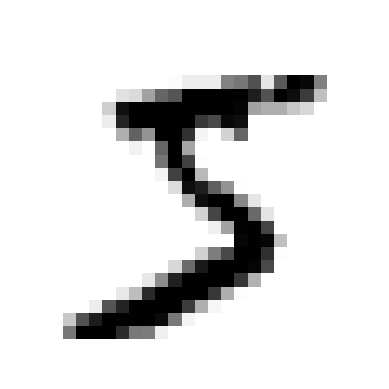

In [6]:
import matplotlib.pyplot as plt


def plot_image(image: np.ndarray) -> None:
    plt.imshow(image, cmap="binary")
    plt.axis("off")
    plt.show()


plot_image(X_train[0])

La función `plot_image()` recibe una imagen de NumPy y la muestra como una imagen visual, en lugar de presentar los valores numéricos de cada píxel.

- `import matplotlib.pyplot as plt`: importa el módulo de gráficos de Matplotlib con el alias `plt`.
- `def plot_image(image: np.ndarray) -> None:` define una función que recibe un array de NumPy y no devuelve ningún valor.
- `plt.imshow(image, cmap="binary")`: representa la matriz como una imagen. El parámetro `cmap="binary"` utiliza una escala de grises en la que los valores bajos aparecen blancos y los valores altos, negros.
- `plt.axis("off")`: oculta los ejes y sus marcas para mostrar únicamente la imagen.
- `plt.show()`: muestra la representación gráfica.

Finalmente, `plot_image(X_train[0])` representa visualmente la primera imagen del conjunto de entrenamiento.

### Conceptos clave

- **Matplotlib:** biblioteca de Python utilizada para crear gráficos y visualizaciones.
- **`imshow()`:** representa una matriz como una imagen.
- **`cmap`:** permite elegir el mapa de colores utilizado para representar los valores.
- **`axis("off")`:** oculta los ejes del gráfico.
- **`X_train[0]`:** selecciona la primera imagen del conjunto de entrenamiento.

**Idea fundamental:** los valores numéricos de los píxeles pueden visualizarse como una imagen para comprobar qué dígito representa cada muestra del conjunto MNIST.

In [7]:
y_train[0]

np.uint8(5)

La expresión `y_train[0]` selecciona la primera etiqueta del conjunto de entrenamiento. Esta etiqueta indica qué dígito representa la primera imagen, `X_train[0]`.

En MNIST, las etiquetas son números enteros del 0 al 9.

- `X_train[0]`: contiene los píxeles de la primera imagen.
- `y_train[0]`: contiene el dígito que representa esa imagen.

### Conceptos clave

- **`cmap`**: determina cómo se representan visualmente los valores numéricos.
- **`binary` y `gray`**: son mapas de colores diferentes; modifican la visualización, no los datos originales.
- **`y_train[0]`**: permite consultar la etiqueta asociada a la primera imagen.
- **Correspondencia entre datos y etiquetas**: cada imagen de `X_train` tiene una etiqueta correspondiente en `y_train`.

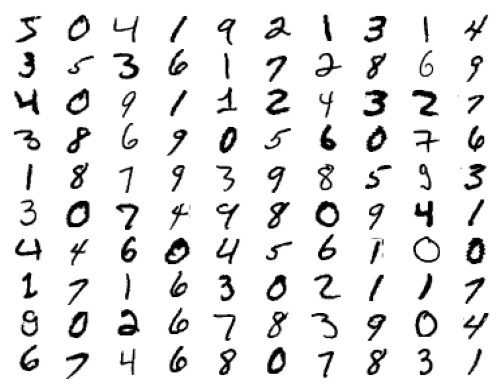

In [8]:
def plot_first_100(images: np.ndarray) -> None:
    for index, image in enumerate(images[:100]):
        plt.subplot(10, 10, index + 1)
        plt.imshow(image, cmap="binary")
        plt.axis("off")
    plt.subplots_adjust(wspace=0, hspace=0)
    plt.show()


plot_first_100(X_train)

### Las primeras 100 imágenes del conjunto de entrenamiento.

La función `plot_first_100()` representa las primeras 100 imágenes del conjunto de datos MNIST en una cuadrícula de 10 filas y 10 columnas.

- `def plot_first_100(images: np.ndarray) -> None:` define una función que recibe un array de NumPy y no devuelve ningún valor.
- `images[:100]` selecciona las primeras 100 imágenes del array.
- `enumerate(images[:100])` recorre las imágenes y proporciona dos valores en cada iteración: el índice (`index`) y la imagen (`image`).
- `plt.subplot(10, 10, index + 1)` divide la figura en una cuadrícula de 10 filas y 10 columnas y selecciona la posición correspondiente a cada imagen. Se suma 1 al índice porque las posiciones de los subgráficos empiezan en 1.
- `plt.imshow(image, cmap="binary")` representa cada imagen utilizando una escala de blanco y negro.
- `plt.axis("off")` oculta los ejes de cada subgráfico.
- `plt.subplots_adjust(wspace=0, hspace=0)` elimina el espacio horizontal (`wspace`) y vertical (`hspace`) entre los subgráficos.
- `plt.show()` muestra la figura completa.

Finalmente, `plot_first_100(X_train)` llama a la función y muestra las primeras 100 imágenes del conjunto de entrenamiento.

### Conceptos clave

- **`enumerate()`**: permite recorrer una colección obteniendo tanto el índice como el elemento.
- **Slicing (`[:100]`)**: selecciona los primeros 100 elementos de un array.
- **`subplot()`**: permite organizar varios gráficos dentro de una misma figura.
- **`subplots_adjust()`**: modifica el espacio entre los subgráficos.
- **Visualización de datos**: representar varias imágenes simultáneamente facilita observar los ejemplos y comprobar la variedad de dígitos del conjunto MNIST.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------

## Ejercicios

### Shapes and indexing

**1.** Crea `matrix_first_100_labels`, una matriz de 10×10 que contenga las primeras 100 etiquetas, y muéstrala por pantalla. Debe coincidir con la cuadrícula de imágenes anterior.

In [9]:
matrix_first_100_labels = y_train[:100].reshape(10, 10)
matrix_first_100_labels

array([[5, 0, 4, 1, 9, 2, 1, 3, 1, 4],
       [3, 5, 3, 6, 1, 7, 2, 8, 6, 9],
       [4, 0, 9, 1, 1, 2, 4, 3, 2, 7],
       [3, 8, 6, 9, 0, 5, 6, 0, 7, 6],
       [1, 8, 7, 9, 3, 9, 8, 5, 9, 3],
       [3, 0, 7, 4, 9, 8, 0, 9, 4, 1],
       [4, 4, 6, 0, 4, 5, 6, 1, 0, 0],
       [1, 7, 1, 6, 3, 0, 2, 1, 1, 7],
       [9, 0, 2, 6, 7, 8, 3, 9, 0, 4],
       [6, 7, 4, 6, 8, 0, 7, 8, 3, 1]], dtype=uint8)

- `y_train[:100]`: selecciona las primeras 100 etiquetas del conjunto de entrenamiento.
- `.reshape(10, 10)`: reorganiza las 100 etiquetas en una matriz de 10 filas y 10 columnas.
- `matrix_first_100_labels`: muestra la matriz resultante en un entorno como Jupyter Notebook.

El objetivo es organizar las etiquetas de los primeros 100 dígitos del conjunto de datos MNIST en una matriz de 10×10 para poder compararlas con sus imágenes correspondientes. Cada etiqueta indica qué número representa una imagen, del 0 al 9.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**2.** Muchos modelos esperan que cada ejemplo se represente como una única fila de números: cada imagen de 28×28 píxeles se convierte en un vector de 784 píxeles. Crea `X_train_flat` y `X_test_flat`, con dimensiones de 60.000×784 y 10.000×784, respectivamente.

In [10]:
X_train_flat = X_train.reshape(len(X_train), -1)
X_test_flat = X_test.reshape(len(X_test), -1)
X_train_flat.shape, X_test_flat.shape

((60000, 784), (10000, 784))

- `len(X_train)`: obtiene el número de imágenes del conjunto de entrenamiento (60.000).
- `len(X_test)`: obtiene el número de imágenes del conjunto de prueba (10.000).
- `.reshape(len(X_train), -1)`: transforma cada imagen en una fila de 784 valores, conservando las 60.000 imágenes. El valor `-1` indica a NumPy que calcule automáticamente el número de columnas necesario.
- `X_train_flat`: almacena las imágenes de entrenamiento transformadas.
- `X_test_flat`: almacena las imágenes de prueba transformadas.
- `.shape`: devuelve las dimensiones de ambas matrices.



El objetivo es convertir las imágenes de MNIST, originalmente representadas como matrices de 28×28 píxeles, en vectores de 784 valores. Así, cada imagen ocupa una fila y cada píxel una columna, lo que facilita el uso de los datos en muchos algoritmos de aprendizaje automático. Se mantiene el número original de imágenes de ambos conjuntos.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**3.** Modifica la función `plot_image` para que acepte tanto una imagen de 28×28 píxeles como una fila plana de 784 píxeles. Comprueba su funcionamiento con `X_train_flat[0]`.

In [11]:
def plot_image(image: np.ndarray) -> None:
    """Plot an MNIST image from either 28x28 or flattened 784 format."""
    if image.ndim == 1:
        side = int(np.sqrt(image.size))
        image = image.reshape(side, side)
    plt.imshow(image, cmap="binary")
    plt.axis("off")
    plt.show()



- `def plot_image(image: np.ndarray) -> None:` define una función que recibe una imagen representada mediante un array de NumPy. `-> None` indica que la función no devuelve un valor, sino que muestra la imagen.
- `image.ndim == 1`: comprueba si la imagen es un array unidimensional, es decir, una fila de píxeles.
- `image.size`: obtiene el número total de elementos del array.
- `np.sqrt(image.size)`: calcula la raíz cuadrada del número de píxeles. Para una imagen de 784 píxeles, el resultado es 28.
- `int(...)`: convierte el resultado en un número entero.
- `image.reshape(side, side)`: transforma la fila de 784 píxeles en una matriz de 28×28.
- `plt.imshow(image, cmap="binary")`: muestra la imagen utilizando una escala de blanco y negro.
- `plt.axis("off")`: oculta los ejes y sus marcas.
- `plt.show()`: presenta la imagen en pantalla.

### Comprobación

Para comprobar que la función funciona con una imagen almacenada en formato plano, ejecuta:

```python
plot_image(X_train_flat[0])
```

Esta instrucción selecciona la primera imagen del conjunto de entrenamiento aplanado. La función detecta que tiene una sola dimensión, la reorganiza en una matriz de 28×28 píxeles y la muestra.

El objetivo es adaptar `plot_image` para que pueda mostrar imágenes de MNIST en sus dos formatos: una matriz bidimensional de 28×28 píxeles o un array unidimensional de 784 valores. Así, la misma función sirve para visualizar imágenes antes y después de aplanarlas.

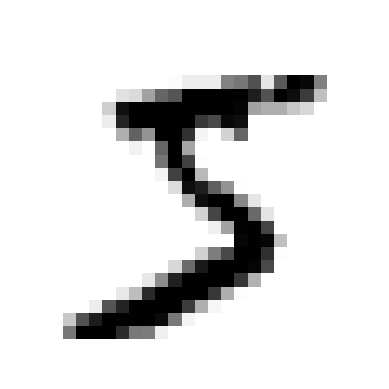

In [12]:
plot_image(X_train_flat[0])

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------

**4.** Comprueba, mediante una única expresión y sin utilizar ningún bucle, que el píxel de la esquina inferior derecha tiene el valor `0` en todas las imágenes de entrenamiento.

In [13]:
np.all(X_train[:, -1, -1] == 0)

np.True_

- `X_train`: contiene las imágenes del conjunto de entrenamiento de MNIST, con dimensiones de 60.000 × 28 × 28.
- `:`: selecciona todas las imágenes del conjunto de entrenamiento.
- `-1`: selecciona la última fila de píxeles.
- `-1`: selecciona el último píxel de esa fila, situado en la esquina inferior derecha.
- `X_train[:, -1, -1] == 0`: comprueba si ese píxel vale `0` en cada imagen y genera un array de valores booleanos (`True` o `False`).
- `np.all(...)`: devuelve `True` únicamente si todas las comprobaciones son verdaderas.

Si el resultado es `True`, significa que el píxel de la esquina inferior derecha vale `0` en todas las imágenes de entrenamiento.

El objetivo es comprobar una propiedad común a todas las imágenes utilizando indexación de NumPy y la función `np.all()`, sin necesidad de recorrerlas con un bucle. La expresión permite verificar simultáneamente los 60.000 valores de ese píxel.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------

**5.** ¿Hay algún dígito que toque el borde de su marco? Guarda en `n_touching_border` el número de imágenes de entrenamiento que contienen tinta (algún píxel distinto de cero) en su primera o última fila o columna.

In [14]:
border = np.zeros((28, 28), dtype=bool)
border[[0, -1], :] = True
border[:, [0, -1]] = True

n_touching_border = int(X_train[:, border].any(axis=1).sum())
n_touching_border

813

**1. Crear una máscara para identificar los bordes**

- `np.zeros((28, 28), dtype=bool)`: crea una matriz de 28×28 con todos sus valores inicializados en `False`.
- `border[[0, -1], :] = True`: marca como `True` la primera y la última fila.
- `border[:, [0, -1]] = True`: marca como `True` la primera y la última columna.

La variable `border` funciona como una máscara booleana que identifica los píxeles situados en el borde de la imagen.

**2. Contar las imágenes que tocan el borde**

- `X_train[:, border]`: selecciona los píxeles del borde de todas las imágenes de entrenamiento.
- `.any(axis=1)`: comprueba si cada imagen tiene al menos un píxel distinto de cero en el borde.
- `.sum()`: cuenta cuántas imágenes cumplen esa condición, ya que NumPy considera `True` como `1` y `False` como `0`.
- `int(...)`: convierte el resultado en un número entero.
- `n_touching_border`: almacena el número total de imágenes que tienen tinta en algún píxel del borde.

### Alternativa equivalente

En esta alternativa:

- `X_train[:, 0, :]`: selecciona la primera fila de todas las imágenes.
- `X_train[:, -1, :]`: selecciona la última fila.
- `X_train[:, :, 0]`: selecciona la primera columna.
- `X_train[:, :, -1]`: selecciona la última columna.
- `.any(axis=1)`: comprueba si hay algún píxel distinto de cero en cada borde.
- `|`: representa el operador lógico **OR** y permite combinar las cuatro comprobaciones.
- `.sum()`: cuenta las imágenes que cumplen al menos una de las condiciones.

In [15]:
touches_border = (
    X_train[:, 0, :].any(axis=1)
    | X_train[:, -1, :].any(axis=1)
    | X_train[:, :, 0].any(axis=1)
    | X_train[:, :, -1].any(axis=1)
)
int(touches_border.sum())

813

Ambas soluciones permiten obtener el mismo resultado.

El objetivo es contar cuántas imágenes del conjunto de entrenamiento contienen algún píxel distinto de cero en su contorno. La primera solución utiliza una máscara booleana para identificar el borde; la segunda comprueba directamente las cuatro filas y columnas exteriores. En ambos casos se aprovechan las operaciones vectorizadas de NumPy, sin necesidad de utilizar bucles explícitos.

### Data types

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**6.** Calcula `X_train[0] + X_train[0]` y observa su valor máximo. Después, calcula la misma suma correctamente y guarda en `n_overflowed_pixels` el número de píxeles cuyos resultados son diferentes en ambas operaciones. ¿Por qué se producen estas diferencias?

In [16]:
doubled_uint8 = X_train[0] + X_train[0]
doubled_uint8.max()

np.uint8(254)

**1. Realizar la suma con el tipo de dato original**

- `X_train[0]`: selecciona la primera imagen del conjunto de entrenamiento.
- `X_train[0] + X_train[0]`: suma cada píxel consigo mismo.
- `doubled_uint8`: almacena el resultado utilizando el tipo de dato original, que habitualmente es `uint8`.
- `doubled_uint8.max()`: devuelve el valor máximo de los píxeles después de la suma.

El tipo `uint8` permite almacenar números enteros sin signo entre 0 y 255. Si una suma supera 255, se produce un **desbordamiento (overflow)**: el resultado vuelve a empezar desde 0.


In [17]:
doubled = X_train[0].astype(np.int32) + X_train[0]
n_overflowed_pixels = int((doubled_uint8 != doubled).sum())
doubled.max(), n_overflowed_pixels

(np.int32(510), 111)

**2. Realizar la suma correctamente**

- `X_train[0].astype(np.int32)`: convierte los píxeles de la primera imagen al tipo entero `int32`, que permite representar valores mucho mayores.
- `X_train[0].astype(np.int32) + X_train[0]`: realiza la suma utilizando un tipo de dato que evita el desbordamiento en este caso.
- `doubled.max()`: obtiene el valor máximo de la imagen duplicada correctamente.

**3. Contar los píxeles afectados**

- `doubled_uint8 != doubled`: compara ambos resultados píxel a píxel y devuelve `True` donde son diferentes.
- `.sum()`: cuenta cuántos píxeles presentan diferencias.
- `int(...)`: convierte el recuento en un número entero.
- `n_overflowed_pixels`: almacena el número de píxeles afectados por el desbordamiento.

Finalmente, `doubled.max(), n_overflowed_pixels` muestra una tupla con el valor máximo de la suma correcta y el número de píxeles cuyos resultados difieren.

### ¿Por qué se producen las diferencias?

El problema se debe al rango limitado del tipo `uint8`.

Por ejemplo, si un píxel tiene el valor `200`:

- **Suma con `uint8`:** \(200 + 200 = 400\). Como 400 supera 255, el resultado se desborda y queda en 144.
- **Suma con `int32`:** \(200 + 200 = 400\). El resultado se conserva correctamente.

En el primer caso, el desbordamiento sigue la aritmética modular: \(400 \bmod 256 = 144\).

El objetivo es comprobar cómo el tipo de dato puede afectar a los resultados de una operación numérica. Al sumar una imagen consigo misma utilizando `uint8`, los píxeles cuya suma supera 255 sufren un desbordamiento. Al convertir previamente los valores a `int32`, se evita este problema. La variable `n_overflowed_pixels` permite contar los píxeles afectados por esta diferencia.

### One-hot encoding

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**7.** Algunos modelos esperan que cada etiqueta se represente mediante un vector *one-hot*: diez números, todos iguales a `0` excepto un `1` en la posición correspondiente al dígito. La etiqueta `5` se convierte en `[0, 0, 0, 0, 0, 1, 0, 0, 0, 0]`.

Crea `y_train_onehot` y `y_test_onehot`.

In [18]:
y_train_onehot = np.zeros((len(y_train), 10))
y_train_onehot[np.arange(len(y_train)), y_train] = 1
y_train_onehot[0]

array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.])

**1. Crear las etiquetas *one-hot* del conjunto de entrenamiento**

- `len(y_train)`: obtiene el número de etiquetas de entrenamiento, que normalmente es 60.000.
- `np.zeros((len(y_train), 10))`: crea una matriz de 60.000 filas y 10 columnas, inicializadas a cero.
- `np.arange(len(y_train))`: genera los índices de las filas, desde `0` hasta `59.999`.
- `y_train`: contiene el dígito correcto de cada imagen, con valores del `0` al `9`.
- `y_train_onehot[np.arange(len(y_train)), y_train] = 1`: coloca un `1` en la columna correspondiente al dígito de cada fila, dejando los demás valores a cero.
- `y_train_onehot[0]`: muestra el vector *one-hot* de la primera etiqueta de entrenamiento.

In [19]:
y_test_onehot = np.eye(10)[y_test]
y_test_onehot[0]

array([0., 0., 0., 0., 0., 0., 0., 1., 0., 0.])

**2. Crear las etiquetas *one-hot* del conjunto de prueba**

- `np.eye(10)`: genera una matriz identidad de 10×10, con unos en la diagonal principal y ceros en el resto.
- `[y_test]`: selecciona de esa matriz la fila correspondiente a cada etiqueta del conjunto de prueba.
- `y_test_onehot`: almacena la matriz de etiquetas transformadas, normalmente de dimensiones 10.000×10.
- `y_test_onehot[0]`: muestra el vector *one-hot* de la primera etiqueta de prueba.

### Ejemplo

Si la etiqueta original es el número `5`, su representación *one-hot* será:

```python
[0., 0., 0., 0., 0., 1., 0., 0., 0., 0.]
```

La posición del `1` indica qué dígito representa la imagen. Como la numeración de las posiciones empieza en cero, el dígito `5` ocupa la sexta posición.

El objetivo es convertir las etiquetas numéricas de MNIST en vectores *one-hot* de diez elementos, uno por cada dígito posible del `0` al `9`. Se crean representaciones independientes para entrenamiento y prueba. Esta codificación es habitual en modelos de clasificación, especialmente en redes neuronales que trabajan con varias clases.

### Normalisation and standardisation

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**8.** Muestra el valor mínimo, el valor máximo, la media y la desviación estándar de los píxeles de las imágenes de entrenamiento.

In [20]:
X_train.min(), X_train.max(), X_train.mean(), X_train.std()

(np.uint8(0),
 np.uint8(255),
 np.float64(33.318421449829934),
 np.float64(78.56748998339798))

### Explicación del código

- `X_train.min()`: devuelve el valor mínimo de todos los píxeles de las imágenes de entrenamiento.
- `X_train.max()`: devuelve el valor máximo de todos los píxeles.
- `X_train.mean()`: calcula la media aritmética de los valores de todos los píxeles.
- `X_train.std()`: calcula la desviación estándar, que mide cuánto se dispersan los valores de los píxeles respecto a su media.

Las cuatro operaciones se aplican directamente a todo el array `X_train`, sin necesidad de utilizar bucles. NumPy procesa todos los valores de las imágenes.

### Resultado esperado

Si las imágenes MNIST conservan sus valores originales, el mínimo será `0` y el máximo `255`. La media y la desviación estándar dependerán de los valores de los píxeles del conjunto de entrenamiento.

El objetivo es obtener estadísticas descriptivas básicas de los píxeles de las imágenes MNIST. Estos valores permiten conocer su rango y distribución, algo útil para comprender los datos antes de entrenar un modelo de aprendizaje automático.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**9.** Escala las imágenes de entrenamiento al rango `[0, 1]` y guarda el resultado en `X_train_norm`, utilizando el tipo de dato `float32`. Después, representa gráficamente la primera imagen.

In [21]:
X_train_norm = X_train.astype(np.float32) / 255
X_train_norm.dtype, X_train_norm.min(), X_train_norm.max()

(dtype('float32'), np.float32(0.0), np.float32(1.0))

**1. Normalizar las imágenes**

- `X_train.astype(np.float32)`: convierte los valores de los píxeles al tipo de dato `float32`, que permite trabajar con números decimales.
- `/ 255`: divide cada píxel entre 255, el valor máximo de la escala original. De esta forma, los valores pasan del rango `[0, 255]` al rango `[0, 1]`.
- `X_train_norm`: almacena las imágenes normalizadas, conservando sus dimensiones originales.

**2. Comprobar la normalización**

```python
X_train_norm.dtype, X_train_norm.min(), X_train_norm.max()
```

- `.dtype`: comprueba el tipo de dato utilizado.
- `.min()`: devuelve el valor mínimo de los píxeles normalizados.
- `.max()`: devuelve el valor máximo.

El tipo de dato esperado es `float32`. Los valores mínimo y máximo estarán dentro del intervalo `[0, 1]`.


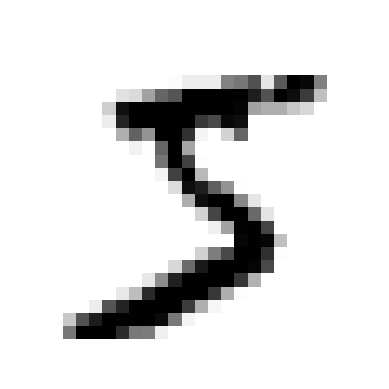

In [22]:
plot_image(X_train_norm[0])

**3. Mostrar la primera imagen**

```python
plot_image(X_train_norm[0])
```

- `X_train_norm[0]`: selecciona la primera imagen normalizada.
- `plot_image(...)`: utiliza la función definida anteriormente para mostrarla.

La imagen mantiene su aspecto original, aunque sus píxeles ahora tienen valores entre `0` y `1` en lugar de entre `0` y `255`.

El objetivo es normalizar las imágenes de entrenamiento para facilitar el procesamiento numérico durante el aprendizaje automático. Al convertir los píxeles a `float32` y dividirlos entre 255, se obtiene una representación decimal en el rango `[0, 1]`. Finalmente, se comprueba el resultado y se visualiza la primera imagen.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**10.** Guarda en `pixel_norm_mean` y `pixel_norm_std` la media y la desviación estándar de los píxeles de `X_train_norm`. Volverás a encontrarte con estos dos valores más adelante.

In [23]:
pixel_norm_mean = X_train_norm.mean()
pixel_norm_std = X_train_norm.std()
pixel_norm_mean, pixel_norm_std

(np.float32(0.13066047), np.float32(0.3081078))

- `X_train_norm.mean()`: calcula la media aritmética de todos los píxeles de las imágenes de entrenamiento normalizadas.
- `X_train_norm.std()`: calcula la desviación estándar de esos mismos píxeles, que mide cuánto se dispersan sus valores respecto a la media.
- `pixel_norm_mean`: almacena la media de los píxeles normalizados.
- `pixel_norm_std`: almacena la desviación estándar de los píxeles normalizados.
- `pixel_norm_mean, pixel_norm_std`: muestra ambos valores en una tupla.

Como las imágenes se han normalizado previamente al rango `[0, 1]`, estas estadísticas se calculan sobre los valores normalizados, no sobre los valores originales entre `0` y `255`.

El objetivo es obtener y almacenar dos estadísticas descriptivas del conjunto de entrenamiento normalizado. Estos valores pueden utilizarse posteriormente para realizar una normalización adicional de los datos, por ejemplo, mediante la estandarización de los píxeles.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**11.** *Estandariza* las imágenes: resta la media y divide entre la desviación estándar para que los píxeles tengan una media de 0 y una desviación estándar de 1.


La fórmula de estandarización es:

$$
X_{std} = \frac{X - \mu}{\sigma}
$$

Crea `X_train_standardized` y `X_test_standardized`. Calcula \(\mu\) (la media) y \(\sigma\) (la desviación estándar) utilizando únicamente las imágenes de entrenamiento, y utiliza esos mismos dos valores para estandarizar las imágenes de prueba.

In [24]:
train_mean = X_train.mean()
train_std = X_train.std()

X_train_standardized = (X_train - train_mean) / train_std
X_test_standardized = (X_test - train_mean) / train_std

X_train_standardized.mean(), X_train_standardized.std()

(np.float64(-3.650352884666855e-17), np.float64(1.0))

In [25]:
X_test_standardized.mean(), X_test_standardized.std()

(np.float64(0.006017794892848059), np.float64(1.007700045387937))

**1. Calcular la media y la desviación estándar del entrenamiento**

- `X_train.mean()`: calcula la media de todos los píxeles de las imágenes de entrenamiento.
- `X_train.std()`: calcula la desviación estándar de esos píxeles.
- `train_mean` y `train_std`: almacenan los dos valores que se utilizarán para estandarizar ambos conjuntos.

**2. Estandarizar las imágenes de entrenamiento**

```python
X_train_standardized = (X_train - train_mean) / train_std
```

- `X_train - train_mean`: resta la media a cada píxel.
- `/ train_std`: divide cada resultado entre la desviación estándar.
- `X_train_standardized`: almacena las imágenes transformadas.

El resultado tendrá una media aproximadamente igual a `0` y una desviación estándar aproximadamente igual a `1`.

**3. Estandarizar las imágenes de prueba**

```python
X_test_standardized = (X_test - train_mean) / train_std
```

Se aplican los mismos valores `train_mean` y `train_std` calculados con los datos de entrenamiento.

Esto es importante porque calcular estadísticas diferentes para el conjunto de prueba introduciría una transformación distinta y podría provocar una evaluación menos coherente del modelo.

**4. Comprobar los resultados**

```python
X_train_standardized.mean(), X_train_standardized.std()

X_test_standardized.mean(), X_test_standardized.std()
```

- `.mean()`: calcula la media de los píxeles estandarizados.
- `.std()`: calcula su desviación estándar.

En el conjunto de entrenamiento se espera obtener una media cercana a `0` y una desviación estándar cercana a `1`. En el conjunto de prueba, los valores serán normalmente próximos, pero no tienen por qué coincidir exactamente con `0` y `1`, ya que se utilizan las estadísticas del entrenamiento.

El objetivo es estandarizar las imágenes para que sus píxeles estén expresados en relación con la media y la desviación estándar del conjunto de entrenamiento. A diferencia de la normalización del ejercicio anterior, que transforma los valores al rango `[0, 1]`, la estandarización genera valores que pueden ser negativos o positivos. Utilizar las estadísticas del entrenamiento en ambos conjuntos evita introducir información del conjunto de prueba durante el preprocesamiento.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**12.** Estandariza `X_train_norm`, las imágenes escaladas al rango `[0, 1]`, de la misma manera y guarda el resultado en `X_train_norm_standardized`. Comprueba con `np.allclose` que es igual a `X_train_standardized`. ¿Por qué deben ser iguales?

In [26]:
X_train_norm_standardized = (X_train_norm - X_train_norm.mean()) / X_train_norm.std()
np.allclose(X_train_norm_standardized, X_train_standardized, atol=1e-5)

True

**1. Estandarizar las imágenes normalizadas**

- `X_train_norm`: contiene las imágenes cuyos píxeles se han escalado al rango `[0, 1]`.
- `X_train_norm.mean()`: calcula la media de los píxeles normalizados.
- `X_train_norm.std()`: calcula su desviación estándar.
- `(X_train_norm - X_train_norm.mean()) / X_train_norm.std()`: resta la media y divide entre la desviación estándar.
- `X_train_norm_standardized`: almacena el resultado de la estandarización.

**2. Comparar los resultados**

- `np.allclose(a, b)`: comprueba si dos arrays tienen valores aproximadamente iguales, teniendo en cuenta una tolerancia numérica.
- `atol=1e-5`: establece una tolerancia absoluta de `0.00001` para considerar iguales los valores comparados.
- El resultado será `True` si todos los elementos de ambos arrays son suficientemente próximos.

### ¿Por qué deben ser iguales?

La normalización del ejercicio anterior consiste en dividir cada píxel entre `255`. Si \(X\) representa los valores originales, entonces:

$
X_{\text{norm}}=\frac{X}{255}
$

Al calcular la media y la desviación estándar de los valores normalizados, obtenemos:

$
\mu_{\text{norm}}=\frac{\mu}{255},
\qquad
\sigma_{\text{norm}}=\frac{\sigma}{255}
$

Por tanto, al estandarizar las imágenes normalizadas:

$$
\frac{X_{\text{norm}}-\mu_{\text{norm}}}
{\sigma_{\text{norm}}}
=
\frac{\frac{X}{255}-\frac{\mu}{255}}
{\frac{\sigma}{255}}
=
\frac{X-\mu}{\sigma}
$$

El factor `255` se cancela en la operación. Por eso, ambos procedimientos producen los mismos valores, salvo pequeñas diferencias debidas a la precisión numérica.

El objetivo es comprobar que escalar los píxeles al rango `[0, 1]` antes de estandarizarlos no cambia el resultado final, siempre que la media y la desviación estándar se calculen sobre los mismos datos. La función `np.allclose` permite verificar esta equivalencia teniendo en cuenta posibles errores de redondeo.

### Loops and vectorisation

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**13.** Escribe la función `normalize_with_loops(images)`, que escale las imágenes al rango `[0, 1] utilizando bucles de Python sobre cada píxel, como se haría sin NumPy.

Mide el tiempo de ejecución y compáralo con la operación vectorizada `images / 255`, utilizando las primeras 1.000 imágenes de entrenamiento y `time.perf_counter`. Guarda en `speedup` cuántas veces más rápida es la versión vectorizada.

El repositorio `compare-python-c-efficiency` explica de dónde procede esta diferencia de rendimiento.

In [27]:
def normalize_with_loops(images: np.ndarray) -> np.ndarray:
    normalized = np.empty(images.shape, dtype=np.float64)
    for index in range(images.shape[0]):
        for row in range(images.shape[1]):
            for col in range(images.shape[2]):
                normalized[index, row, col] = images[index, row, col] / 255
    return normalized

**1. Crear la función de normalización con bucles**

- `def normalize_with_loops(images: np.ndarray) -> np.ndarray:` define una función que recibe un array de imágenes y devuelve otro array con los valores normalizados.
- `np.empty(images.shape, dtype=np.float64)`: reserva memoria para almacenar los resultados, conservando las dimensiones de las imágenes. Los valores se inicializan posteriormente mediante los bucles.
- `images.shape[0]`: indica el número de imágenes.
- `images.shape[1]`: indica el número de filas de cada imagen.
- `images.shape[2]`: indica el número de columnas de cada imagen.
- Los tres bucles `for` recorren todas las imágenes, sus filas y sus columnas.
- `images[index, row, col] / 255`: divide cada píxel entre 255 para transformar sus valores al rango `[0, 1]`.
- `normalized[index, row, col] = ...`: guarda el resultado en la posición correspondiente.
- `return normalized`: devuelve el array normalizado.

In [28]:
import time

sample = X_train[:1000]

start = time.perf_counter()
normalized_with_loops = normalize_with_loops(sample)
loops_seconds = time.perf_counter() - start

start = time.perf_counter()
normalized_vectorized = sample / 255
vectorized_seconds = time.perf_counter() - start

speedup = loops_seconds / vectorized_seconds
np.allclose(normalized_with_loops, normalized_vectorized), speedup

(True, 100.2078951351195)

**2. Seleccionar las primeras 1.000 imágenes**

```python
sample = X_train[:1000]
```

`X_train[:1000]` selecciona las primeras 1.000 imágenes del conjunto de entrenamiento. Cada imagen tiene 28×28 píxeles, por lo que se procesan un total de 784.000 píxeles.

**3. Medir el tiempo de los bucles**

```python
start = time.perf_counter()
normalized_with_loops = normalize_with_loops(sample)
loops_seconds = time.perf_counter() - start
```

- `time.perf_counter()`: proporciona un contador de alta resolución adecuado para medir duraciones.
- `start`: almacena el instante inicial.
- `normalize_with_loops(sample)`: ejecuta la normalización mediante los tres bucles.
- `time.perf_counter() - start`: calcula el tiempo transcurrido en segundos.
- `loops_seconds`: guarda la duración de esta operación.

**4. Medir el tiempo de la versión vectorizada**

```python
start = time.perf_counter()
normalized_vectorized = sample / 255
vectorized_seconds = time.perf_counter() - start
```

- `sample / 255`: divide todos los píxeles entre 255 en una única operación de NumPy, sin escribir bucles explícitos en Python.
- `vectorized_seconds`: almacena el tiempo que tarda esta operación.

**5. Calcular la mejora de velocidad**

```python
speedup = loops_seconds / vectorized_seconds
```

La variable `speedup` indica cuántas veces más rápida es la versión vectorizada respecto a la versión con bucles.

Por ejemplo, si los bucles tardan 2 segundos y la operación vectorizada tarda 0,02 segundos, el resultado será `100`: la versión vectorizada es 100 veces más rápida.

**6. Comprobar que ambas versiones producen el mismo resultado**

```python
np.allclose(normalized_with_loops, normalized_vectorized), speedup
```

- `np.allclose(...)`: comprueba si los dos arrays contienen valores aproximadamente iguales.
- `speedup`: muestra la mejora de velocidad calculada.

El primer resultado debería ser `True`, ya que ambas implementaciones realizan la misma normalización.

### ¿Por qué NumPy es más rápido?

Los bucles de Python ejecutan repetidamente instrucciones a nivel de lenguaje para acceder a cada píxel, realizar la división y almacenar el resultado.

NumPy, en cambio, utiliza operaciones vectorizadas implementadas principalmente en código compilado, que procesa los datos sin ejecutar un bucle de Python por cada píxel. Esto reduce la sobrecarga de interpretación y permite trabajar con grandes cantidades de datos de forma mucho más eficiente.

El objetivo es comparar dos formas de realizar la misma tarea: normalizar los píxeles mediante tres bucles explícitos de Python y hacerlo con una operación vectorizada de NumPy. Con `time.perf_counter` se mide el tiempo de ambas versiones, `speedup` cuantifica la mejora de rendimiento y `np.allclose` verifica que los resultados son equivalentes.

### Data augmentation

*Data augmentation* creates new training examples by transforming the ones you have: a digit shifted a few pixels, or with some noise, is still the same digit. A model trained on the augmented set sees more variety and generalises better. Deep-learning libraries do it for you; here you do it by hand.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**14.** Escribe la función `add_gaussian_noise(images, std)`, que añada ruido aleatorio procedente de una distribución normal con media `0` y desviación estándar `std` a cada píxel, y devuelva imágenes del mismo tipo de dato y rango que la entrada (`uint8`, de `0` a `255`).

Crea `X_train_noisy` utilizando `std=50` y representa gráficamente las primeras 100 imágenes.

> **El ruido gaussiano es un ruido aleatorio que sigue una distribución normal.** Se puede aplicar a las imágenes para simular condiciones de captura no ideales. Esto puede ayudar a que los modelos de aprendizaje automático sean más robustos.
>
> `rng = np.random.default_rng(seed=0)` crea un generador de números aleatorios, y `rng.normal` obtiene valores de una distribución normal. La semilla hace que el ruido sea el mismo cada vez que se ejecuta el cuaderno.

In [29]:
rng = np.random.default_rng(seed=0)


def add_gaussian_noise(images: np.ndarray, std: float) -> np.ndarray:
    """Add Gaussian noise to images and clip to valid range."""
    noise = rng.normal(loc=0.0, scale=std, size=images.shape)
    return np.clip(images + noise, 0, 255).astype(np.uint8)


X_train_noisy = add_gaussian_noise(X_train, std=50)

**1. Crear el generador de números aleatorios**

- `np.random.default_rng(seed=0)`: crea un generador de números aleatorios con una semilla fija.
- `rng`: permite generar ruido reproducible. Si se ejecuta el cuaderno desde el mismo estado inicial, se obtendrá la misma secuencia de valores aleatorios.

**2. Definir la función de ruido gaussiano**

- `def add_gaussian_noise(images: np.ndarray, std: float) -> np.ndarray:` define una función que recibe un conjunto de imágenes y la desviación estándar del ruido que se añadirá.
- `rng.normal(loc=0.0, scale=std, size=images.shape)`: genera valores aleatorios siguiendo una distribución normal.
  - `loc=0.0`: establece la media del ruido en cero.
  - `scale=std`: establece su desviación estándar.
  - `size=images.shape`: genera tantos valores de ruido como píxeles contienen las imágenes, conservando sus dimensiones.
- `images + noise`: suma el ruido a cada píxel de las imágenes originales.
- `np.clip(images + noise, 0, 255)`: limita los resultados al intervalo `[0, 255]`. Esto evita valores fuera del rango válido de los píxeles.
- `.astype(np.uint8)`: convierte los valores resultantes al tipo de dato original, `uint8`.

**3. Crear las imágenes con ruido**

```python
X_train_noisy = add_gaussian_noise(X_train, std=50)
```

- `X_train`: proporciona las imágenes originales de entrenamiento.
- `std=50`: establece la desviación estándar del ruido. Cuanto mayor sea este valor, más intensas serán, en general, las variaciones de los píxeles.
- `X_train_noisy`: almacena las imágenes resultantes con ruido añadido.

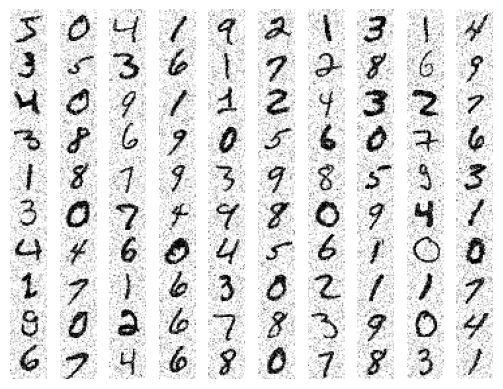

In [30]:
plot_first_100(X_train_noisy)

**4. Mostrar las primeras 100 imágenes**

```python
plot_first_100(X_train_noisy)
```

La función `plot_first_100` muestra las primeras 100 imágenes del conjunto modificado para observar visualmente cómo afecta el ruido a los dígitos.

El objetivo es simular imágenes capturadas en condiciones imperfectas mediante la incorporación de ruido gaussiano. La función genera ruido con media cero y desviación estándar 50, lo suma a cada píxel y limita los valores al rango válido de `uint8`. Finalmente, se muestran las primeras 100 imágenes para observar el efecto.

Esta técnica también puede utilizarse como **aumento de datos (*data augmentation*)**: entrenar modelos con imágenes modificadas puede ayudarles a reconocer dígitos incluso cuando las imágenes presentan ruido o pequeñas alteraciones.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**15.** Escribe la función `binarize_image(image, threshold)`, que devuelva `1` cuando un píxel sea mayor que `threshold` y `0` en caso contrario, utilizando el tipo de dato `uint8`. La función debe funcionar tanto con una única imagen como con un array completo de imágenes.

Crea `X_train_binarized` utilizando un umbral de `128` y representa gráficamente las primeras 100 imágenes.

In [31]:
def binarize_image(image: np.ndarray, threshold: int) -> np.ndarray:
    return (image > threshold).astype(np.uint8)


X_train_binarized = binarize_image(X_train, threshold=128)

**1. Definir la función de binarización**

- `def binarize_image(image: np.ndarray, threshold: int) -> np.ndarray:` define una función que recibe una imagen o un conjunto de imágenes y un umbral numérico.
- `image > threshold`: compara cada píxel con el umbral y genera un array booleano. Los píxeles mayores que el umbral se convierten en `True`; los demás, en `False`.
- `.astype(np.uint8)`: convierte los valores booleanos en números enteros de 8 bits sin signo: `True` pasa a `1` y `False` pasa a `0`.
- `return`: devuelve el array binarizado.

**2. Crear las imágenes binarizadas**

```python
X_train_binarized = binarize_image(X_train, threshold=128)
```

- `X_train`: contiene las imágenes originales de entrenamiento.
- `threshold=128`: establece el umbral de binarización. Solo los píxeles estrictamente mayores que `128` tendrán valor `1`.
- `X_train_binarized`: almacena las imágenes transformadas, conservando sus dimensiones originales.

La función trabaja con todas las imágenes simultáneamente gracias a las operaciones vectorizadas de NumPy, sin necesidad de utilizar bucles explícitos.

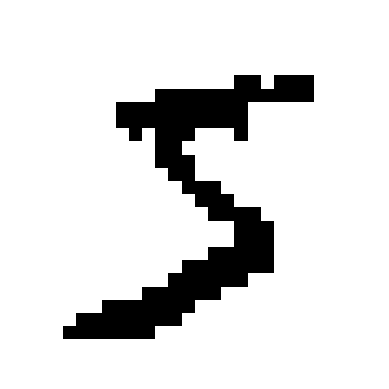

In [32]:
plot_image(X_train_binarized[0])

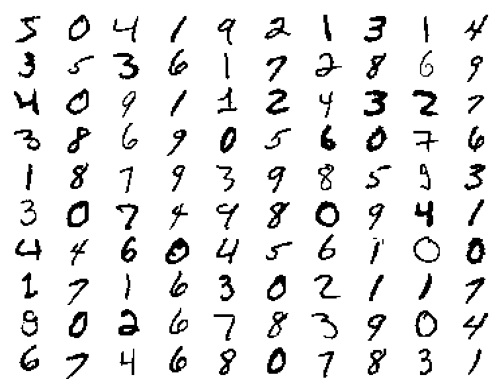

In [33]:
plot_first_100(X_train_binarized)

**3. Mostrar una imagen**

```python
plot_image(X_train_binarized[0])
```

Selecciona la primera imagen del conjunto binarizado y la muestra para comprobar visualmente el resultado.

**4. Mostrar las primeras 100 imágenes**

```python
plot_first_100(X_train_binarized)
```

Representa las primeras 100 imágenes para observar cómo afecta la binarización al conjunto de entrenamiento.

El objetivo es transformar las imágenes de MNIST en imágenes binarias, con solo dos valores posibles: `0` y `1`. Los píxeles superiores al umbral de `128` se convierten en `1`, mientras que los inferiores o iguales se convierten en `0`.

Esta transformación simplifica la información visual y permite estudiar cómo influye la eliminación de los niveles intermedios de intensidad en la representación de los dígitos.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**16.** Representa gráficamente las primeras 100 imágenes de entrenamiento binarizadas con los umbrales `80` y `180`, utilizando una celda para cada umbral. ¿Qué cambios se observan?

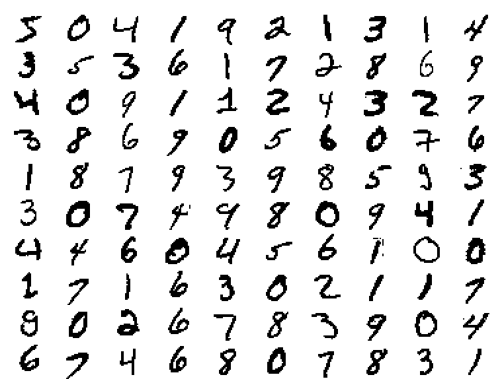

In [34]:
plot_first_100(binarize_image(X_train, threshold=80))

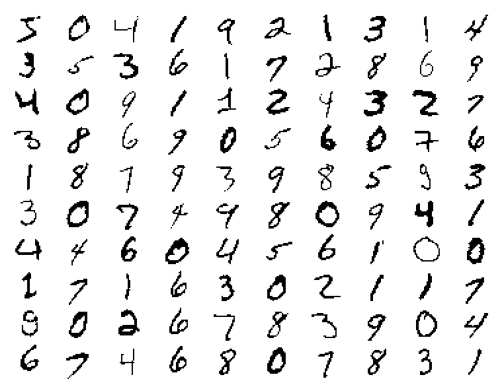

In [35]:
plot_first_100(binarize_image(X_train, threshold=180))

### Explicación del código

- `binarize_image(X_train, threshold=80)`: convierte a `1` los píxeles cuyo valor es superior a `80` y a `0` los demás.
- `binarize_image(X_train, threshold=180)`: convierte a `1` los píxeles cuyo valor es superior a `180` y a `0` los demás.
- `plot_first_100(...)`: muestra las primeras 100 imágenes después de aplicar la binarización.

Cada celda utiliza un umbral diferente para observar cómo cambia la representación de los dígitos.

### ¿Qué cambios se observan?

- **Umbral 80:** más píxeles superan el umbral y se convierten en `1`. Por tanto, los trazos de los dígitos tienden a aparecer más gruesos y se conserva más información de las zonas con intensidad moderada.
- **Umbral 180:** menos píxeles superan el umbral. Los trazos tienden a ser más finos y algunas partes débiles de los dígitos pueden desaparecer.

El objetivo es comprobar cómo influye el umbral en la binarización de las imágenes. Un umbral bajo conserva más píxeles como `1`, mientras que uno alto exige una intensidad mayor. Elegir un umbral adecuado permite controlar qué partes de los dígitos se conservan y cuáles se eliminan.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**17.** Crea `X_train_noisy_binarized` binarizando las imágenes con ruido utilizando el umbral `128` y representa gráficamente las primeras 100 imágenes. Prueba otros umbrales: ¿cuál elimina la mayor parte del ruido sin deteriorar los dígitos?

In [36]:
X_train_noisy_binarized = binarize_image(X_train_noisy, threshold=128)

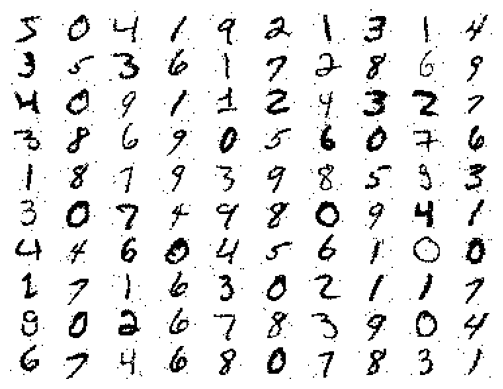

In [37]:
plot_first_100(X_train_noisy_binarized)

### Explicación del código

- `X_train_noisy`: contiene las imágenes de entrenamiento a las que se ha añadido ruido gaussiano.
- `binarize_image(X_train_noisy, threshold=128)`: transforma las imágenes en binarias. Los píxeles con valores superiores a `128` se convierten en `1`; los demás, en `0`.
- `X_train_noisy_binarized`: almacena las imágenes binarizadas después de añadirles ruido.
- `plot_first_100(...)`: muestra las primeras 100 imágenes para comprobar visualmente el resultado.

Para probar otros umbrales, puedes ejecutar el siguiente código en celdas independientes:

```python
plot_first_100(binarize_image(X_train_noisy, threshold=100))
```

```python
plot_first_100(binarize_image(X_train_noisy, threshold=150))
```

```python
plot_first_100(binarize_image(X_train_noisy, threshold=180))
```

### ¿Qué umbral elimina mejor el ruido?

El resultado depende de la intensidad del ruido y de los valores de los píxeles originales.

- **Umbral bajo:** más píxeles se convierten en `1`, por lo que puede conservar mejor los trazos, pero también mantener parte del ruido.
- **Umbral alto:** menos píxeles se convierten en `1`, lo que puede eliminar puntos de ruido, pero también hacer desaparecer partes de los dígitos.
- **Umbral intermedio:** puede ofrecer un equilibrio entre eliminar el ruido y conservar la forma de los números.

No existe un umbral universalmente óptimo. Hay que comparar las imágenes obtenidas y elegir el que reduzca el ruido sin borrar trazos importantes. Como el ruido gaussiano puede tanto aumentar como disminuir la intensidad de los píxeles, la binarización no elimina necesariamente todo el ruido.

Este ejercicio combina dos transformaciones: primero se añade ruido a las imágenes y después se aplica la binarización. El objetivo es comprobar si un umbral adecuado permite reducir visualmente el ruido y mantener reconocibles los dígitos de MNIST.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**18.** Escribe la función `shift_image(image, dx, dy)`, que desplaza una imagen `dx` píxeles hacia la derecha (o hacia la izquierda si el valor es negativo) y `dy` píxeles hacia abajo (o hacia arriba si el valor es negativo). Los espacios que queden vacíos deben rellenarse con ceros.

Representa la primera imagen desplazada 10 píxeles en cada una de las cuatro direcciones, utilizando una celda independiente para cada representación.

In [38]:
def shift_image(image: np.ndarray, dx: int, dy: int) -> np.ndarray:
    height, width = image.shape
    shifted = np.zeros_like(image)
    destination_rows = slice(max(dy, 0), height + min(dy, 0))
    destination_cols = slice(max(dx, 0), width + min(dx, 0))
    source_rows = slice(max(-dy, 0), height + min(-dy, 0))
    source_cols = slice(max(-dx, 0), width + min(-dx, 0))
    shifted[destination_rows, destination_cols] = image[source_rows, source_cols]
    return shifted

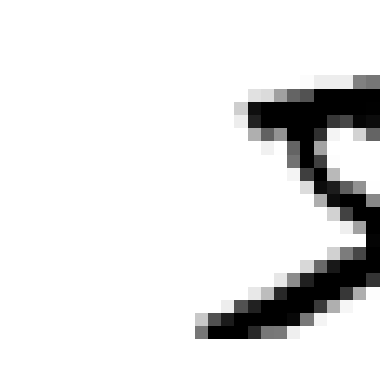

In [39]:
plot_image(shift_image(X_train[0], dx=10, dy=0))

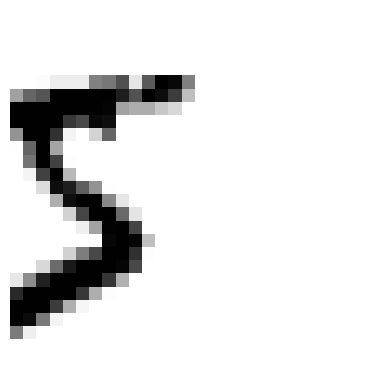

In [40]:
plot_image(shift_image(X_train[0], dx=-10, dy=0))

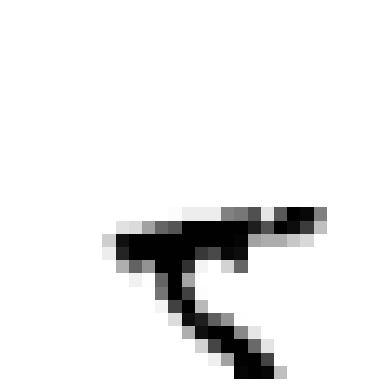

In [41]:
plot_image(shift_image(X_train[0], dx=0, dy=10))

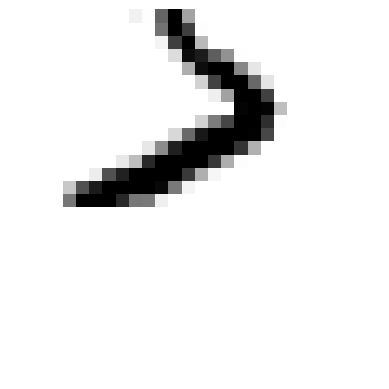

In [42]:
plot_image(shift_image(X_train[0], dx=0, dy=-10))

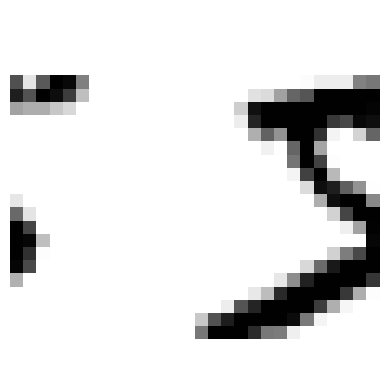

In [43]:
plot_image(np.roll(X_train[0], 10, axis=1))

### Explicación del código

- `height, width = image.shape`: obtiene la altura y la anchura de la imagen.
- `np.zeros_like(image)`: crea una imagen del mismo tamaño y tipo de datos, rellenada con ceros. Será el destino del desplazamiento.
- `slice(...)`: define los intervalos de filas y columnas que se utilizarán para copiar los píxeles.
- `max(dy, 0)` y `min(dy, 0)`: calculan los límites de las filas de destino según el desplazamiento vertical.
- `max(dx, 0)` y `min(dx, 0)`: calculan los límites de las columnas de destino según el desplazamiento horizontal.
- `source_rows` y `source_cols`: determinan qué parte de la imagen original se debe copiar para que el desplazamiento se realice en la dirección correcta.
- `shifted[destination_rows, destination_cols] = image[source_rows, source_cols]`: copia los píxeles de la imagen original a sus nuevas posiciones. Los espacios que quedan fuera de la zona copiada mantienen el valor `0`.
- `return shifted`: devuelve la imagen desplazada.

### ¿Por qué no utilizar `np.roll()`?

También se podría probar:

```python
plot_image(np.roll(X_train[0], 10, axis=1))
```

Sin embargo, `np.roll()` desplaza los píxeles de forma circular: los que salen por un extremo reaparecen por el extremo opuesto. Esto no cumple el enunciado, que exige rellenar los espacios vacíos con ceros.

La función `shift_image()` desplaza una imagen sin modificar su tamaño y rellena con ceros las zonas vacías. Los parámetros `dx` y `dy` permiten controlar la dirección y la distancia del desplazamiento. Esta técnica puede utilizarse para generar variaciones de las imágenes de MNIST y ampliar los datos de entrenamiento, una técnica conocida como *aumento de datos* (*data augmentation*).

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**19.** Crea `X_train_shifted_right_10`, desplazando todas las imágenes de entrenamiento 10 píxeles hacia la derecha, y representa gráficamente las primeras 100. Algunos dígitos aparecen cortados: ¿cuáles y por qué?

In [44]:
X_train_shifted_right_10 = np.array([shift_image(image, dx=10, dy=0) for image in X_train])

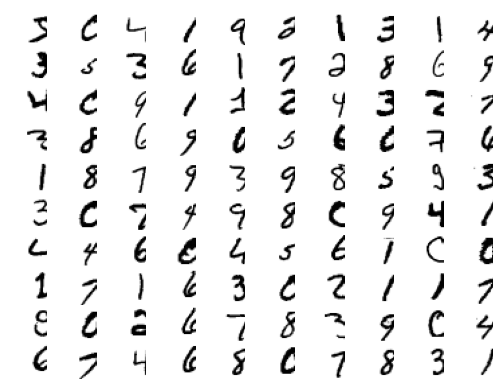

In [45]:
plot_first_100(X_train_shifted_right_10)

**1. Desplazar todas las imágenes**

- `for image in X_train`: recorre todas las imágenes del conjunto de entrenamiento.
- `shift_image(image, dx=10, dy=0)`: desplaza cada imagen 10 píxeles a la derecha, sin movimiento vertical.
- `np.array([...])`: reúne las imágenes desplazadas en un único array llamado `X_train_shifted_right_10`.
- `plot_first_100(...)`: muestra las primeras 100 imágenes para observar el efecto del desplazamiento.

In [46]:
shifted_by_slicing = np.zeros_like(X_train)
shifted_by_slicing[:, :, 10:] = X_train[:, :, :-10]
np.array_equal(shifted_by_slicing, X_train_shifted_right_10)

True

**2. Realizar el desplazamiento mediante slicing**

- `np.zeros_like(X_train)`: crea un array del mismo tamaño que `X_train`, rellenado con ceros.
- `shifted_by_slicing[:, :, 10:]`: selecciona, para todas las imágenes y todas las filas, las columnas desde la número 10 hasta el final.
- `X_train[:, :, :-10]`: selecciona las columnas originales excepto las 10 últimas.
- La asignación copia los píxeles a sus nuevas posiciones, dejando a cero las primeras 10 columnas.
- `np.array_equal(...)`: comprueba si ambos métodos producen exactamente los mismos valores. Si devuelve `True`, los resultados son idénticos.

### ¿Qué dígitos aparecen cortados y por qué?

Los dígitos que tienen trazos cerca del borde derecho son los que pueden perder parte de su forma al desplazarse 10 píxeles hacia la derecha.

Las imágenes de MNIST tienen un tamaño de **28 × 28 píxeles**. Al desplazar una imagen, los píxeles que salen por el borde derecho se pierden y no reaparecen por el lado izquierdo: el espacio vacío se rellena con ceros.

Por tanto, pueden quedar cortados distintos dígitos, dependiendo de su posición original. No se puede afirmar que sean siempre los mismos números; hay que observar las imágenes resultantes.

Este ejercicio aplica un desplazamiento horizontal a todo el conjunto de entrenamiento y compara dos formas de implementarlo: mediante la función `shift_image()` y mediante slicing de NumPy. El desplazamiento puede cortar los trazos que salen del límite de la imagen, lo que puede dificultar el reconocimiento del dígito.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**20.** Escribe la función `find_limits(image)`, que devuelve una tupla `(top, bottom, left, right)` con las primeras y últimas filas y columnas que contienen tinta (píxeles distintos de cero).

Comprueba que la primera imagen de entrenamiento devuelve `(5, 24, 4, 23)`. Después, representa la imagen dibujando sus límites mediante `plt.axhline` y `plt.axvline`.

In [47]:
def find_limits(image: np.ndarray) -> tuple[int, int, int, int]:
    rows_with_ink = np.flatnonzero(image.any(axis=1))
    cols_with_ink = np.flatnonzero(image.any(axis=0))
    return int(rows_with_ink[0]), int(rows_with_ink[-1]), int(cols_with_ink[0]), int(cols_with_ink[-1])


find_limits(X_train[0])

(5, 24, 4, 23)

**1. Función `find_limits()`**

- `image.any(axis=1)`: comprueba qué filas contienen al menos un píxel distinto de cero.
- `image.any(axis=0)`: comprueba qué columnas contienen al menos un píxel distinto de cero.
- `np.flatnonzero(...)`: devuelve los índices de los elementos que cumplen la condición.
- `rows_with_ink[0]` y `rows_with_ink[-1]`: obtienen la primera y la última fila con tinta.
- `cols_with_ink[0]` y `cols_with_ink[-1]`: obtienen la primera y la última columna con tinta.
- `int(...)`: convierte los valores de NumPy en enteros de Python.
- `return`: devuelve los cuatro límites en el orden solicitado.

In [48]:
def find_limits_from_pixels(image: np.ndarray) -> tuple[int, int, int, int]:
    rows, cols = np.nonzero(image)
    return int(rows.min()), int(rows.max()), int(cols.min()), int(cols.max())


find_limits_from_pixels(X_train[0])

(5, 24, 4, 23)

**2. Función `find_limits_from_pixels()`**

Esta función obtiene el mismo resultado mediante otro procedimiento:

- `np.nonzero(image)`: devuelve las coordenadas de las filas y columnas de todos los píxeles distintos de cero.
- `rows.min()` y `rows.max()`: encuentran las filas mínima y máxima.
- `cols.min()` y `cols.max()`: encuentran las columnas mínima y máxima.

Ambas funciones deberían devolver la misma tupla para una imagen que contenga tinta.

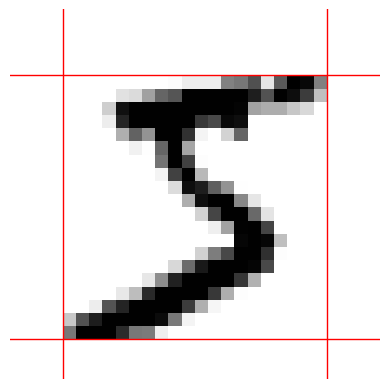

In [50]:
def plot_with_limits(image: np.ndarray) -> None:
    top, bottom, left, right = find_limits(image)
    plt.imshow(image, cmap="binary")
    for row in (top -0.5, bottom + 0.5):
        plt.axhline(row, color="red", linewidth=1)
    for col in (left - 0.5, right + 0.5):
        plt.axvline(col, color="red", linewidth=1)
    plt.axis("off")
    plt.show()


plot_with_limits(X_train[0])

**3. Función `plot_with_limits()`**

- `plt.imshow(image, cmap="binary")`: muestra la imagen en blanco y negro.
- `plt.axhline(...)`: dibuja líneas horizontales rojas en las filas superior e inferior.
- `plt.axvline(...)`: dibuja líneas verticales rojas en las columnas izquierda y derecha.
- `plt.axis("off")`: oculta los ejes.
- `plt.show()`: muestra la representación.

Las cuatro líneas delimitan el rectángulo mínimo que contiene todos los píxeles con tinta.



Este ejercicio permite detectar automáticamente la zona ocupada por un dígito dentro de una imagen. Las funciones `find_limits()` y `find_limits_from_pixels()` utilizan métodos distintos, pero obtienen los mismos límites. Esta información puede utilizarse para recortar imágenes, centrar dígitos o preparar los datos antes de entrenar un modelo de reconocimiento.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**21.** Escribe la función `crop_image_limits(image)`, que devuelve la imagen recortada según sus límites. ¿Qué dimensiones tiene la primera imagen de entrenamiento después de recortarla y por qué? Recuerda cómo se construyó el conjunto de datos MNIST.

In [49]:
def crop_image_limits(image: np.ndarray) -> np.ndarray:
    top, bottom, left, right = find_limits(image)
    return image[top:bottom + 1, left:right + 1]


crop_image_limits(X_train[0]).shape

(20, 20)

### Explicación del código

- `find_limits(image)`: obtiene las coordenadas de la primera y última fila y columna que contienen tinta, utilizando la función del ejercicio anterior.
- `top, bottom, left, right`: almacenan los cuatro límites de la imagen.
- `image[top:bottom + 1, left:right + 1]`: selecciona únicamente la región que contiene el dígito.

**¿Por qué se suma 1 a `bottom` y `right`?**

En Python, el límite final de un slicing no se incluye. Por eso, para conservar también la última fila y la última columna con tinta, hay que sumarles uno.

- `.shape`: devuelve las dimensiones de la imagen recortada.
- `plot_image(...)`: muestra el resultado para comprobar visualmente el recorte.

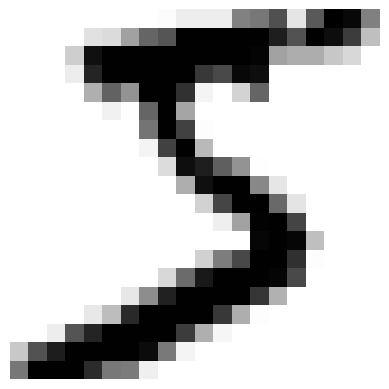

In [50]:
plot_image(crop_image_limits(X_train[0]))

### ¿Qué dimensiones tiene la imagen recortada y por qué?

La primera imagen original de MNIST tiene un tamaño de **28 × 28 píxeles**. Según los límites obtenidos en el ejercicio anterior:

- Filas: desde la 5 hasta la 24, ambas incluidas: \(24 - 5 + 1 = 20\).
- Columnas: desde la 4 hasta la 23, ambas incluidas: \(23 - 4 + 1 = 20\).

Por tanto, el resultado esperado es:

```python
(20, 20)
```

El recorte elimina los márgenes exteriores que no contienen tinta y conserva el rectángulo mínimo que incluye el dígito.

MNIST se construyó a partir de imágenes de dígitos manuscritos que se normalizaron y centraron en imágenes de tamaño fijo de 28 × 28 píxeles. Sin embargo, ese centrado no significa que todos los dígitos ocupen toda la imagen ni que tengan las mismas dimensiones efectivas. Por eso, al eliminar los márgenes vacíos, cada imagen recortada puede tener un tamaño diferente.

La función `crop_image_limits()` recorta una imagen para conservar únicamente la región que contiene el dígito. En la primera imagen, el resultado esperado es de **20 × 20 píxeles**, frente a los 28 × 28 originales. Esto demuestra que las imágenes de MNIST tienen dimensiones uniformes, aunque los dígitos ocupen áreas diferentes dentro de ellas.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**22.** Crea `X_train_shifted`, desplazando cada imagen de entrenamiento una cantidad aleatoria de píxeles en cada dirección, pero sin permitir que la tinta salga del marco de la imagen. Utiliza `find_limits` para determinar cuánto puede desplazarse cada dígito.

In [51]:
def random_shift(image: np.ndarray) -> np.ndarray:
    height, width = image.shape
    top, bottom, left, right = find_limits(image)
    dy = rng.integers(-top, height - bottom)
    dx = rng.integers(-left, width - right)
    return shift_image(image, dx=dx, dy=dy)


X_train_shifted = np.array([random_shift(image) for image in X_train])

**1. Obtener las dimensiones y los límites**

- `height, width = image.shape`: obtiene la altura y la anchura de la imagen.
- `top, bottom, left, right = find_limits(image)`: identifica los límites del dígito, es decir, las primeras y últimas filas y columnas que contienen tinta.

**2. Calcular el desplazamiento vertical**

```python
dy = rng.integers(-top, height - bottom)
```

Determina un desplazamiento vertical aleatorio.

- Si `dy` es negativo, el dígito se desplaza hacia arriba.
- Si `dy` es positivo, se desplaza hacia abajo.
- Si es cero, no se mueve verticalmente.

Los límites calculados evitan que la tinta salga del marco. `rng.integers()` incluye el límite inferior, pero excluye el superior.

**3. Calcular el desplazamiento horizontal**

```python
dx = rng.integers(-left, width - right)
```

Calcula el desplazamiento horizontal permitido.

- Si `dx` es negativo, el dígito se desplaza hacia la izquierda.
- Si `dx` es positivo, se desplaza hacia la derecha.
- Si es cero, permanece en la misma posición horizontal.

Los límites se calculan a partir de la zona que ocupa realmente el dígito, no del tamaño completo de la imagen.

**4. Aplicar el desplazamiento**

```python
return shift_image(image, dx=dx, dy=dy)
```

Utiliza la función del ejercicio 18 para desplazar la imagen y rellenar con ceros los espacios vacíos.

**5. Generar el nuevo conjunto de entrenamiento**

```python
X_train_shifted = np.array([
    random_shift(image)
    for image in X_train
])
```

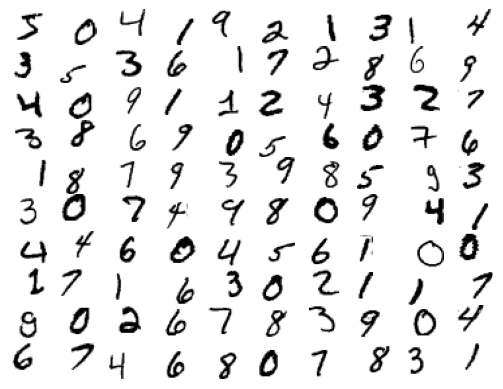

In [52]:
plot_first_100(X_train_shifted)

Recorre todas las imágenes de `X_train`, aplica a cada una un desplazamiento aleatorio y reúne los resultados en un nuevo array.

Finalmente, `plot_first_100(X_train_shifted)` muestra las primeras 100 imágenes transformadas.

Este ejercicio aplica una técnica de aumento de datos (*data augmentation*): crea nuevas variaciones de los dígitos mediante desplazamientos aleatorios. La función `find_limits()` permite calcular cuánto puede moverse cada dígito sin perder tinta fuera de los bordes, conservando así la información necesaria para reconocerlo.

**Nota:** el código presupone que `rng` ya se ha definido como generador aleatorio de NumPy, por ejemplo, mediante `rng = np.random.default_rng(seed=0)`. Con una semilla fija, los desplazamientos se pueden reproducir si se ejecuta el código en el mismo orden.

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**23.** Crea `X_train_augmented` concatenando, en este orden, las imágenes originales de entrenamiento, las imágenes con ruido, las imágenes binarizadas, las imágenes con ruido y binarizadas y las imágenes desplazadas aleatoriamente.

Antes de concatenar, convierte los dos conjuntos de imágenes binarizadas de nuevo al rango de valores de 0 a 255, para que todas las imágenes utilicen la misma escala de píxeles.

Crea `y_train_augmented` con las etiquetas correspondientes. ¿Cuántas imágenes hay en total?

In [53]:
X_train_augmented = np.concatenate([
    X_train,
    X_train_noisy,
    X_train_binarized * 255,
    X_train_noisy_binarized * 255,
    X_train_shifted,
])
y_train_augmented = np.tile(y_train, 5)
X_train_augmented.shape, y_train_augmented.shape

((300000, 28, 28), (300000,))

**1. Concatenar los conjuntos de imágenes**

`np.concatenate([...])` une los cinco conjuntos de imágenes en un único array, respetando el orden indicado:

1. `X_train`: imágenes originales.
2. `X_train_noisy`: imágenes a las que se ha añadido ruido.
3. `X_train_binarized * 255`: imágenes binarizadas.
4. `X_train_noisy_binarized * 255`: imágenes con ruido que después se han binarizado.
5. `X_train_shifted`: imágenes desplazadas aleatoriamente.

**2. Recuperar la escala de las imágenes binarizadas**

La binarización transforma los píxeles en valores `0` y `1`. Al multiplicar por `255`, se convierten en `0` y `255`, igualando el rango de intensidad de las imágenes originales.

Esto no recupera los detalles que se perdieron durante la binarización; únicamente adapta sus valores para mantener una escala común.

**3. Crear las etiquetas correspondientes**

```python
y_train_augmented = np.tile(y_train, 5)
```

`np.tile(y_train, 5)` repite cinco veces el array de etiquetas original. Así, cada versión transformada de una imagen conserva la etiqueta del dígito que representa.

Por ejemplo, si una imagen original representa el número `7`, sus versiones con ruido, binarizadas y desplazadas también tendrán la etiqueta `7`.

**4. Comprobar las dimensiones**

```python
X_train_augmented.shape, y_train_augmented.shape
```

`.shape` devuelve las dimensiones de ambos arrays.

Como MNIST contiene inicialmente **60.000 imágenes de entrenamiento**, y se utilizan cinco versiones de cada imagen:

\[
60.000 \times 5 = 300.000
\]

El resultado esperado es:

```python
((300000, 28, 28), (300000,))
```

- `X_train_augmented`: 300.000 imágenes de 28 × 28 píxeles.
- `y_train_augmented`: 300.000 etiquetas, una por imagen.

Este ejercicio reúne las imágenes originales y cuatro versiones transformadas en un único conjunto de entrenamiento. Las etiquetas se repiten para que cada imagen conserve su clase correcta.

**Resultado: 300.000 imágenes**, cinco veces más que el conjunto original. Esta técnica de aumento de datos permite entrenar modelos con mayor variedad de ejemplos, aunque las imágenes transformadas no aportan necesariamente información completamente nueva.

### Going further

--------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------
**24.** *(Optional, no test.)* Building `X_train_shifted` calls a Python function 60,000 times. Write a version without a loop over the images, and measure the speed-up. Is it worth it? Hint: pad the whole array with zeros once, then take for each image the 28×28 window that matches its offset, with fancy indexing.

In [54]:
def random_shift_all(images: np.ndarray) -> np.ndarray:
    count, height, width = images.shape
    rows_with_ink = images.any(axis=2)
    cols_with_ink = images.any(axis=1)
    top = rows_with_ink.argmax(axis=1)
    bottom = height - 1 - rows_with_ink[:, ::-1].argmax(axis=1)
    left = cols_with_ink.argmax(axis=1)
    right = width - 1 - cols_with_ink[:, ::-1].argmax(axis=1)
    dy = rng.integers(-top, height - bottom)
    dx = rng.integers(-left, width - right)
    padded = np.pad(images, ((0, 0), (height, height), (width, width)))
    rows = height - dy[:, None] + np.arange(height)
    cols = width - dx[:, None] + np.arange(width)
    return padded[np.arange(count)[:, None, None], rows[:, :, None], cols[:, None, :]]

In [55]:
shifted_all = random_shift_all(X_train)
np.array_equal(shifted_all.sum(axis=(1, 2)), X_train.sum(axis=(1, 2)))

True

**5. Comprobar la conservación de la tinta**

La expresión:

```python
np.array_equal(
    shifted_all.sum(axis=(1, 2)),
    X_train.sum(axis=(1, 2))
)
```

compara la suma de los píxeles de cada imagen original con la de su versión desplazada. Si devuelve `True`, todas las sumas coinciden.

Esto sirve como comprobación, pero no demuestra por sí solo que todas las imágenes sean correctas: dos imágenes diferentes pueden tener la misma suma de píxeles.


In [56]:
start = time.perf_counter()
np.array([random_shift(image) for image in X_train[:10_000]])
loop_seconds = time.perf_counter() - start

start = time.perf_counter()
random_shift_all(X_train[:10_000])
vectorized_seconds = time.perf_counter() - start

loop_seconds / vectorized_seconds

1.650702550449618

**6. Medir la aceleración**

`time.perf_counter()` mide el tiempo transcurrido con alta resolución.

El cociente:

$
\text{Aceleración} =
\frac{\text{Tiempo con bucle}}{\text{Tiempo vectorizado}}
$

indica cuántas veces más rápida es la versión vectorizada. Por ejemplo, un resultado de `5` significa que ha sido cinco veces más rápida en esa medición.

### ¿Merece la pena optimizarlo?

La vectorización puede reducir considerablemente el tiempo de ejecución porque evita realizar 10.000 llamadas individuales a una función Python. Sin embargo, también introduce cálculos de índices y reserva memoria para el array ampliado.

La decisión depende del resultado medido:

- **Si la aceleración es grande**, la optimización puede compensar cuando se procesan las 60.000 imágenes o se repite el proceso muchas veces.
- **Si la aceleración es pequeña**, la versión sencilla con el bucle puede ser preferible por su legibilidad.
- **Si se ejecuta una sola vez**, hay que valorar si el ahorro de tiempo justifica la complejidad añadida.

Para una comparación justa, conviene ejecutar varias mediciones, utilizar el mismo conjunto de imágenes y tener en cuenta que las dos versiones consumen números aleatorios diferentes. No es necesario que produzcan los mismos desplazamientos para comparar su velocidad.

Este ejercicio compara dos estrategias: ejecutar una función Python por imagen o aprovechar las operaciones vectorizadas de NumPy para procesar todo el conjunto de una vez. La segunda puede ser más rápida, pero la mejora real debe medirse en el entorno de ejecución.

La conclusión es que **optimizar merece la pena cuando el ahorro medido compensa la complejidad y el consumo de memoria adicionales**.